# HIVE VÀ TRỰC QUAN HÓA 

## PHẦN 1: KẾT NỐI SPARK VỚI HIVE

In [5]:
#Khởi tạo lại Spark và kết nối Hive
from pyspark.sql import SparkSession

BASE = "hdfs://namenode:8020"

spark = (
    SparkSession.builder
    .appName("FIFA-Hive-Visualization")
    .config("spark.hadoop.fs.defaultFS", BASE)
    .config("spark.sql.warehouse.dir", f"{BASE}/user/hive/warehouse")
    .config("hive.metastore.uris", "thrift://hive-metastore:9083")
    .config("spark.sql.parquet.writeLegacyFormat", "true")
    .config("spark.driver.memory", "3g")
    .config("spark.sql.shuffle.partitions", "16")
    .enableHiveSupport()
    .getOrCreate()
)

print("Spark version:", spark.version)
print("SparkSession đã được khởi tạo.")

Spark version: 3.5.0
SparkSession đã được khởi tạo.


In [9]:
# Kiểm tra Database và các bảng Hive
print("=== 1. Các database hiện có ===")
spark.sql("SHOW DATABASES").show(truncate=False)

print("\n=== 2. Chọn database fifa ===")
spark.sql("USE fifa")
print("Đã chọn database fifa.")

print("\n=== 3. Các bảng trong database fifa ===")
spark.sql("SHOW TABLES").show(truncate=False)


=== 1. Các database hiện có ===
+---------+
|namespace|
+---------+
|default  |
|fifa     |
+---------+


=== 2. Chọn database fifa ===
Đã chọn database fifa.

=== 3. Các bảng trong database fifa ===
+---------+---------+-----------+
|namespace|tableName|isTemporary|
+---------+---------+-----------+
+---------+---------+-----------+



In [10]:
# Kiểm tra các file Parquet trong HDFS (Dữ liệu spark trong HDFS)
hadoop_conf = spark.sparkContext._jsc.hadoopConfiguration()
Path = spark.sparkContext._jvm.org.apache.hadoop.fs.Path

fs = Path("hdfs://namenode:8020/").getFileSystem(hadoop_conf)

root = Path("/fifa/processed")

if fs.exists(root):
    print("Đã tìm thấy thư mục /fifa/processed")

    def list_hdfs(path, depth=0):
        for status in fs.listStatus(path):
            name = status.getPath().toString()
            if status.isDirectory():
                print("  " * depth + "[DIR]  " + name)
                list_hdfs(status.getPath(), depth + 1)
            else:
                print("  " * depth + "[FILE] " + name)

    list_hdfs(root)
else:
    print("Chưa tìm thấy /fifa/processed")
    print("Các thư mục tại /fifa:")
    fifa_root = Path("/fifa")
    if fs.exists(fifa_root):
        for item in fs.listStatus(fifa_root):
            print(item.getPath().toString())
    else:
        print("Thư mục /fifa không tồn tại trong HDFS")

Đã tìm thấy thư mục /fifa/processed
[DIR]  hdfs://namenode:8020/fifa/processed/club_summary
  [FILE] hdfs://namenode:8020/fifa/processed/club_summary/_SUCCESS
  [FILE] hdfs://namenode:8020/fifa/processed/club_summary/part-00000-4c16ab5c-42d8-4652-9d6f-683235aa4f68-c000.snappy.parquet
[DIR]  hdfs://namenode:8020/fifa/processed/nationality_summary
  [FILE] hdfs://namenode:8020/fifa/processed/nationality_summary/_SUCCESS
  [FILE] hdfs://namenode:8020/fifa/processed/nationality_summary/part-00000-db30d136-d84d-4470-8cb3-fee09ce9b162-c000.snappy.parquet
[DIR]  hdfs://namenode:8020/fifa/processed/position_summary
  [FILE] hdfs://namenode:8020/fifa/processed/position_summary/_SUCCESS
  [FILE] hdfs://namenode:8020/fifa/processed/position_summary/part-00000-0d68cae2-c9ed-42b9-b3c5-a360aa7ffb4f-c000.snappy.parquet


In [11]:
# Đọc thử dữ liệu và kiểm tra các cột 
base_path = "hdfs://namenode:8020/fifa/processed"

datasets = {
    "club_summary": f"{base_path}/club_summary",
    "nationality_summary": f"{base_path}/nationality_summary",
    "position_summary": f"{base_path}/position_summary"
}

for name, path in datasets.items():
    print("\n" + "=" * 60)
    print(f"BỘ DỮ LIỆU: {name}")
    print("=" * 60)

    df = spark.read.parquet(path)

    print("Cấu trúc cột:")
    df.printSchema()

    print("5 dòng dữ liệu mẫu:")
    df.show(5, truncate=False)

    print("Số dòng:", df.count())


BỘ DỮ LIỆU: club_summary
Cấu trúc cột:
root
 |-- club_name: string (nullable = true)
 |-- total_players: long (nullable = true)
 |-- avg_overall: double (nullable = true)
 |-- avg_wage: double (nullable = true)
 |-- total_value: long (nullable = true)

5 dòng dữ liệu mẫu:
+-------------------+-------------+-----------------+------------------+------------+
|club_name          |total_players|avg_overall      |avg_wage          |total_value |
+-------------------+-------------+-----------------+------------------+------------+
|Real Madrid        |17270        |77.97637521713955|139740.27214823393|442292395000|
|FC Barcelona       |17029        |78.58118503728933|140428.84784778906|424759840000|
|Manchester City    |18226        |75.6339295511906 |103879.9434873258 |412909850000|
|FC Bayern München  |15556        |78.34629724865003|97745.69298020056 |409758030000|
|Paris Saint Germain|15973        |77.21141927001815|78527.1927627872  |360945200000|
+-------------------+-------------+---

# PHẦN 2: TẠO LẬP VÀ KIỂM TRA DỮ LIỆU TRÊN HIVE
## Bước 1: Tạo các bảng Hive

In [16]:
# Đăng ký các bảng Hive từ Parquet trên HDFS
spark.sql("CREATE DATABASE IF NOT EXISTS fifa")

table_paths = {
    "club_summary": "hdfs://namenode:8020/fifa/processed/club_summary",
    "nationality_summary": "hdfs://namenode:8020/fifa/processed/nationality_summary",
    "position_summary": "hdfs://namenode:8020/fifa/processed/position_summary"
}

for table_name, path in table_paths.items():
    spark.sql(f"""
        CREATE TABLE IF NOT EXISTS fifa.{table_name}
        USING PARQUET
        LOCATION '{path}'
    """)
    print(f"Đã kiểm tra/đăng ký bảng: fifa.{table_name}")

print("\nDanh sách bảng Hive:")
spark.sql("SHOW TABLES IN fifa").show(truncate=False)

Đã kiểm tra/đăng ký bảng: fifa.club_summary
Đã kiểm tra/đăng ký bảng: fifa.nationality_summary
Đã kiểm tra/đăng ký bảng: fifa.position_summary

Danh sách bảng Hive:
+---------+-------------------+-----------+
|namespace|tableName          |isTemporary|
+---------+-------------------+-----------+
|fifa     |club_summary       |false      |
|fifa     |nationality_summary|false      |
|fifa     |position_summary   |false      |
+---------+-------------------+-----------+



## Bước 2: Kiểm tra dữ liệu các dòng đầu của bảng Hive
Nếu truy vấn được dữ liệu, phần đăng ký bảng Hive cơ bản đã hoạt động. Tiếp theo, ta sẽ dùng các bảng này để tạo biểu đồ bằng Python.

In [20]:
# Kiểm tra dữ liệu các dòng đầu của bảng Hive
for table_name in ["club_summary", "nationality_summary", "position_summary"]:
    print(f"\n=== {table_name} ===")
    spark.sql(f"SELECT * FROM fifa.{table_name} LIMIT 5").show(truncate=False)


=== club_summary ===
+-------------------+-------------+-----------------+------------------+------------+
|club_name          |total_players|avg_overall      |avg_wage          |total_value |
+-------------------+-------------+-----------------+------------------+------------+
|Real Madrid        |17270        |77.97637521713955|139740.27214823393|442292395000|
|FC Barcelona       |17029        |78.58118503728933|140428.84784778906|424759840000|
|Manchester City    |18226        |75.6339295511906 |103879.9434873258 |412909850000|
|FC Bayern München  |15556        |78.34629724865003|97745.69298020056 |409758030000|
|Paris Saint Germain|15973        |77.21141927001815|78527.1927627872  |360945200000|
+-------------------+-------------+-----------------+------------------+------------+


=== nationality_summary ===
+----------------+-------------+-----------------+-------------+
|nationality_name|total_players|avg_overall      |total_value  |
+----------------+-------------+------------

## PHẦN 3: TRỰC QUAN HÓA DỮ LIỆU FIFA
### 1. Biểu đồ Bar Chart — Top 10 CLB có mức lương trung bình cao nhất
Câu hỏi phân tích: Những CLB nào có mức lương cầu thủ trung bình cao nhất trong bộ dữ liệu FIFA?
### Bước 1: Truy vấn dữ liệu từ Hive

In [21]:
query_bar = """
SELECT
    club_name,
    avg_wage,
    total_players,
    avg_overall
FROM fifa.club_summary
WHERE club_name IS NOT NULL
  AND avg_wage IS NOT NULL
ORDER BY avg_wage DESC
LIMIT 10
"""

df_bar = spark.sql(query_bar)
df_bar.show(truncate=False)

+-------------------+------------------+-------------+-----------------+
|club_name          |avg_wage          |total_players|avg_overall      |
+-------------------+------------------+-------------+-----------------+
|FC Barcelona       |140428.84784778906|17029        |78.58118503728933|
|Real Madrid        |139740.27214823393|17270        |77.97637521713955|
|Real Madrid CF     |119753.34143377886|823          |76.84447144592953|
|Manchester City    |103879.9434873258 |18226        |75.6339295511906 |
|Juventus           |100945.85336934325|15181        |79.55753902904947|
|FC Bayern München  |97745.69298020056 |15556        |78.34629724865003|
|Manchester United  |90580.22178627868 |18351        |76.15367009972209|
|Chelsea            |88875.16372241484 |18171        |75.45385504375103|
|Paris Saint-Germain|87968.11079545454 |704          |77.046875        |
|Paris Saint Germain|78527.1927627872  |15973        |77.21141927001815|
+-------------------+------------------+-----------

### Bước 2: Vẽ biểu đồ 

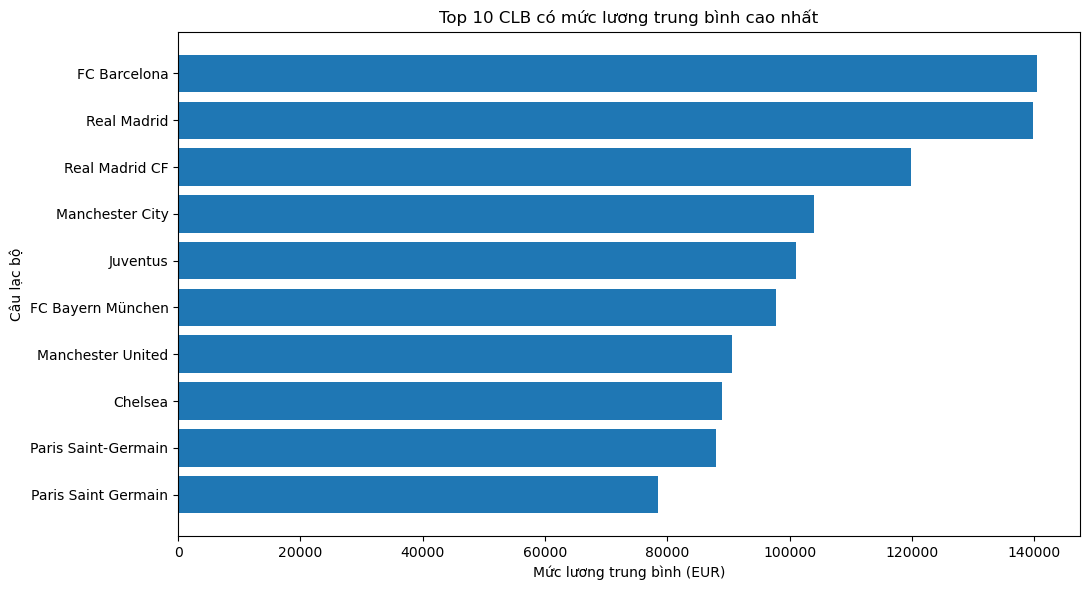

In [23]:
import matplotlib.pyplot as plt

# Chuyển kết quả truy vấn sang Pandas để trực quan hóa
df_bar_pd = df_bar.toPandas()

# Đảo thứ tự để CLB có lương cao nhất nằm ở phía trên
df_bar_pd = df_bar_pd.sort_values(
    "avg_wage", ascending=True
)

plt.figure(figsize=(11, 6))

plt.barh(
    df_bar_pd["club_name"],
    df_bar_pd["avg_wage"]
)

plt.title("Top 10 CLB có mức lương trung bình cao nhất")
plt.xlabel("Mức lương trung bình (EUR)")
plt.ylabel("Câu lạc bộ")
plt.tight_layout()
plt.savefig("top10_club_avg_wage.png", dpi=200, bbox_inches="tight")
plt.show()

### *Kết luận:*
  *- FC Barcelona và Real Madrid là hai CLB có mức lương trung bình cao nhất. Mức lương trung bình của cả hai đều khoảng 140.000 EUR, trong đó FC Barcelona nhỉnh hơn Real Madrid một chút.*
  
  *- Có sự chênh lệch khá rõ giữa nhóm dẫn đầu và các CLB còn lại. Real Madrid CF đứng thứ ba với mức lương trung bình khoảng 120.000 EUR, thấp hơn hai CLB dẫn đầu khoảng 20.000 EUR. Manchester City đứng thứ tư với mức lương khoảng 104.000 EUR.*
  
  *- Các CLB còn lại có mức lương trung bình thấp hơn nhóm dẫn đầu. Juventus đạt khoảng 101.000 EUR, Bayern München khoảng 98.000 EUR, Manchester United khoảng 91.000 EUR, Chelsea và Paris Saint-Germain khoảng 88.000–89.000 EUR. Paris Saint Germain ở cuối Top 10 có mức lương trung bình khoảng 79.000 EUR.*

### 2. Scatter Plot — Mối quan hệ giữa mức lương và năng lực cầu thủ theo CLB
Câu hỏi phân tích: Các CLB có mức lương cầu thủ trung bình cao có đồng thời có điểm Overall trung bình cao không?
### Bước 1: Truy vấn dữ liệu từ Hive

In [24]:
query_scatter = """
SELECT
    club_name,
    avg_wage,
    avg_overall
FROM fifa.club_summary
WHERE club_name IS NOT NULL
  AND avg_wage IS NOT NULL
  AND avg_overall IS NOT NULL
"""

df_scatter = spark.sql(query_scatter)
df_scatter.show(10, truncate=False)

print("Số CLB được đưa vào phân tích:", df_scatter.count())

+-------------------+------------------+-----------------+
|club_name          |avg_wage          |avg_overall      |
+-------------------+------------------+-----------------+
|Real Madrid        |139740.27214823393|77.97637521713955|
|FC Barcelona       |140428.84784778906|78.58118503728933|
|Manchester City    |103879.9434873258 |75.6339295511906 |
|FC Bayern München  |97745.69298020056 |78.34629724865003|
|Paris Saint Germain|78527.1927627872  |77.21141927001815|
|Liverpool          |74018.9771402504  |74.20898170206296|
|Chelsea            |88875.16372241484 |75.45385504375103|
|Manchester United  |90580.22178627868 |76.15367009972209|
|Juventus           |100945.85336934325|79.55753902904947|
|Atlético Madrid    |52538.8239097214  |75.57599623839191|
+-------------------+------------------+-----------------+
only showing top 10 rows

Số CLB được đưa vào phân tích: 1648


### Bước 2: Vẽ biểu đồ

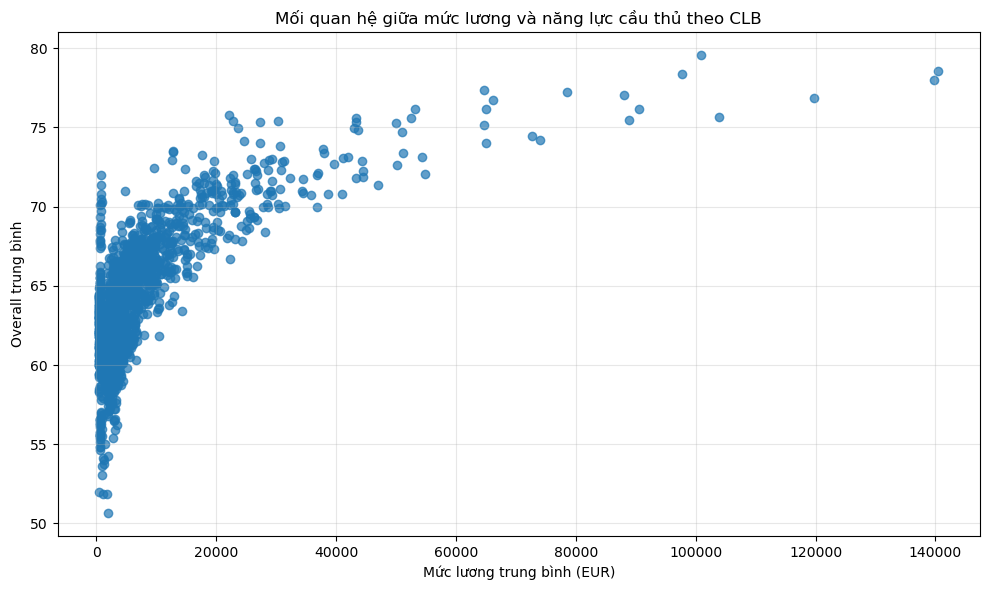

In [25]:
import matplotlib.pyplot as plt

# Chuyển kết quả truy vấn sang Pandas
df_scatter_pd = df_scatter.toPandas()

plt.figure(figsize=(10, 6))

plt.scatter(
    df_scatter_pd["avg_wage"],
    df_scatter_pd["avg_overall"],
    alpha=0.7
)

plt.title("Mối quan hệ giữa mức lương và năng lực cầu thủ theo CLB")
plt.xlabel("Mức lương trung bình (EUR)")
plt.ylabel("Overall trung bình")
plt.grid(True, alpha=0.3)
plt.tight_layout()
plt.savefig("club_wage_vs_overall.png", dpi=200, bbox_inches="tight")
plt.show()

In [26]:
# Tính hệ số tương quan
correlation = df_scatter_pd["avg_wage"].corr(
    df_scatter_pd["avg_overall"]
)

print(f"Hệ số tương quan Pearson: {correlation:.3f}")

Hệ số tương quan Pearson: 0.687


### *Nhận xét: Phân tích mối quan hệ giữa mức lương và năng lực cầu thủ theo câu lạc bộ*

  *-Biểu đồ Scatter Plot cho thấy các điểm dữ liệu có xu hướng phân bố đi lên từ trái sang phải, gợi ý mối quan hệ thuận giữa mức lương trung bình và điểm Overall trung bình của các câu lạc bộ. Phần lớn các CLB tập trung ở vùng có mức lương trung bình thấp và điểm Overall khoảng 60–70, trong khi một số CLB có mức lương trung bình cao hơn cũng đạt điểm Overall trung bình cao hơn.*

  *-Kết quả tính hệ số tương quan Pearson đạt 0,687, cho thấy mối tương quan tuyến tính thuận tương đối rõ giữa hai biến trong bộ dữ liệu được phân tích. Điều này có nghĩa là các CLB có mức lương trung bình cao hơn thường có xu hướng đạt điểm Overall trung bình cao hơn, phù hợp với xu hướng thể hiện trên biểu đồ.*

  *-Tuy nhiên, mối tương quan này không hoàn toàn tuyệt đối và không chứng minh rằng mức lương cao là nguyên nhân làm tăng năng lực cầu thủ. Overall còn có thể liên quan đến nhiều yếu tố khác. Vì vậy, kết quả nên được hiểu là mối liên hệ thống kê giữa mức lương trung bình và điểm Overall trung bình của các CLB trong bộ dữ liệu FIFA.*

# TỔNG KẾT

- **Kết nối Spark với Hive Metastore:** Kiểm tra dữ liệu Parquet trên HDFS và đăng ký 3 bảng tổng hợp: `club_summary`, `nationality_summary`, `position_summary`.

- **Truy vấn dữ liệu:** Thực hiện truy vấn Spark SQL để khai thác dữ liệu từ các bảng Hive.

- **Trực quan hóa dữ liệu:** Xây dựng biểu đồ Bar Chart phân tích Top 10 CLB có mức lương trung bình cao nhất và Scatter Plot khảo sát mối quan hệ giữa mức lương trung bình với điểm Overall trung bình theo CLB.

- **Phân tích tương quan:** Hệ số tương quan Pearson đạt **0,687**, cho thấy mối tương quan tuyến tính thuận tương đối rõ giữa hai biến trong dữ liệu được phiệu FIFA.*liệu FIFA.tích.

> *Nhìn chung, nhiệm vụ đã khai thác dữ liệu tổng hợp, thực hiện truy vấn phân tích và trực quan hóa bằng Bar Chart, Scatter Plot. Kết quả giúp làm rõ sự khác biệt về mức lương giữa các câu lạc bộ và mối tương quan giữa mức lương trung bình với năng lực cầu thủ trung bình trong bộ dữ liệu FIFA.*